<a href="https://colab.research.google.com/github/ajishavs08/machine-learning-algorithms/blob/main/ml_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
from google.colab import files

# Upload the classification CSV dataset
uploaded = files.upload()

# Read the uploaded CSV
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the first rows
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

# Check columns and data types
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())


Saving Social_Network_Ads (1).csv to Social_Network_Ads (1).csv
Dataset loaded successfully!
Dataset shape: (400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0



Column names:
['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Load the dataset
df = pd.read_csv("Social_Network_Ads (1).csv")

# Remove the unique ID because it is not a useful prediction feature
X = df[["Gender", "Age", "EstimatedSalary"]].copy()
y = df["Purchased"]

# Convert categorical Gender values into numeric values
X["Gender"] = X["Gender"].map({"Male": 0, "Female": 1})

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train the classification model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)

# Evaluate the model
print("Classification Algorithm: Logistic Regression")
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Algorithm: Logistic Regression
Training samples: 300
Testing samples: 100
Accuracy: 81.0 %

Confusion Matrix:
[[59  5]
 [14 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.92      0.86        64
           1       0.81      0.61      0.70        36

    accuracy                           0.81       100
   macro avg       0.81      0.77      0.78       100
weighted avg       0.81      0.81      0.80       100



In [3]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))
df_boost = pd.read_csv(file_name)

print("Boosting dataset loaded successfully!")
print("Dataset shape:", df_boost.shape)
display(df_boost.head())

print("\nColumns:")
print(df_boost.columns.tolist())

print("\nMissing values:")
print(df_boost.isnull().sum())


Saving insurance_pre.csv to insurance_pre.csv
Boosting dataset loaded successfully!
Dataset shape: (1338, 6)


,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520



Columns:
['age', 'sex', 'bmi', 'children', 'smoker', 'charges']

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
charges     0
dtype: int64


Algorithm: Gradient Boosting Regressor
Training samples: 1070
Testing samples: 268
MAE: 2428.58
RMSE: 4344.03
R2 Score: 0.8784


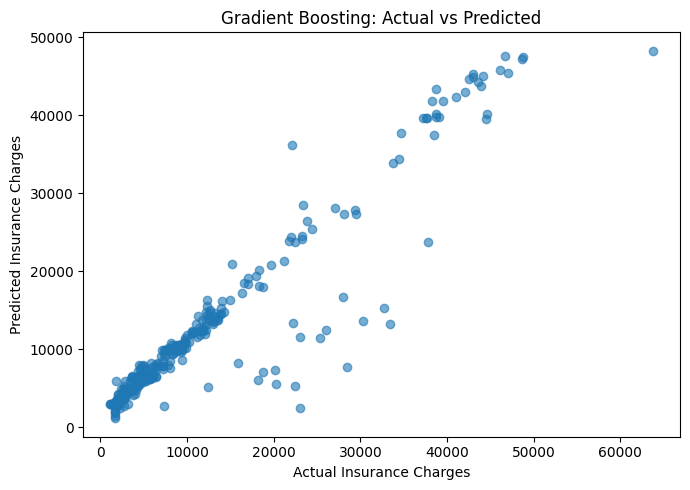

In [5]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load the insurance dataset
df = pd.read_csv("insurance_pre.csv")

# Separate input features and target
X = df.drop(columns=["charges"])
y = df["charges"]

# Identify categorical and numerical columns
categorical_cols = ["sex", "smoker"]
numerical_cols = ["age", "bmi", "children"]

# Preprocess categorical features
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore",
                                  drop="first"), categorical_cols),
    ("numerical", "passthrough", numerical_cols)
])

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build and train the Gradient Boosting model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("boosting", GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1,
        max_depth=3, random_state=42
    ))
])

model.fit(X_train, y_train)

# Predict insurance charges
y_pred = model.predict(X_test)

# Evaluate model performance
print("Algorithm: Gradient Boosting Regressor")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

# Plot actual vs predicted charges
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.tight_layout()
plt.show()



In [6]:

from google.colab import files
import pandas as pd

# Upload the third dataset
uploaded = files.upload()

file_name = next(iter(uploaded))
df_cluster = pd.read_csv(file_name)

print("Clustering dataset loaded successfully!")
print("Dataset shape:", df_cluster.shape)

display(df_cluster.head())

print("\nColumn names:")
print(df_cluster.columns.tolist())

print("\nMissing values:")
print(df_cluster.isnull().sum())


Saving Mall_Customers.csv to Mall_Customers.csv
Clustering dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Algorithm: K-Means Clustering
Number of customers: 200
Number of clusters: 5
Silhouette Score: 0.5547

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


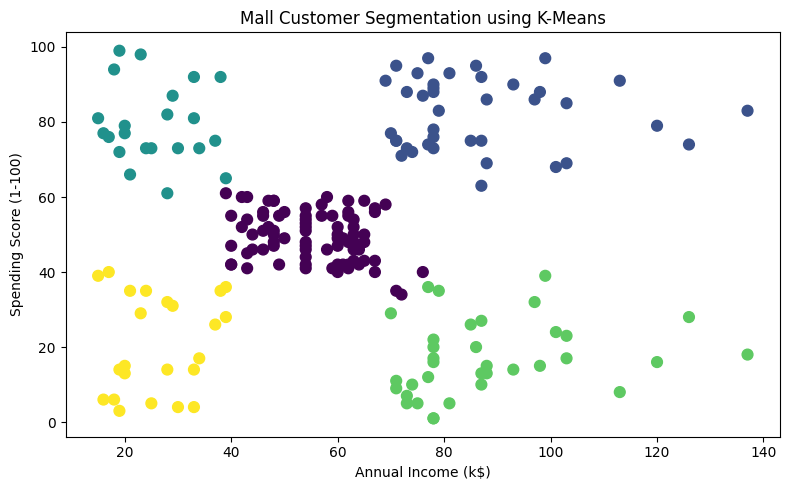

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Load the Mall Customers dataset
df = pd.read_csv("Mall_Customers.csv")

# Select income and spending score for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train the K-Means model with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Evaluate the clustering
score = silhouette_score(X_scaled, df["Cluster"])

print("Algorithm: K-Means Clustering")
print("Number of customers:", len(df))
print("Number of clusters:", df["Cluster"].nunique())
print("Silhouette Score:", round(score, 4))

print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# Visualize customer clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Mall Customer Segmentation using K-Means")
plt.tight_layout()
plt.show()

# Preview cluster assignments
display(df.head())
